In [6]:
# [참고 출처 (Citations)]
# 1. 데이터셋:
#    - Kaggle Food.com Recipes and Interactions
#    - Kaggle Food.com - Recipes and Reviews
# 2. 오픈소스 라이브러리 공식 문서:
#    - scikit-surprise (SVD): https://surprise.readthedocs.io/en/stable/matrix_factorization.html
#    - NumPy (dot, argpartition, clip): https://numpy.org/doc/stable/

# 전처리 완료된 데이터셋 압축 해제 및 파일 확인
!unzip -o 전처리_완료.zip

import os
print("현재 폴더 파일 목록:", os.listdir('.'))

# scikit-surprise: 파이썬 기반 추천 시스템 전용 오픈소스 라이브러리 설치
!pip install scikit-surprise

Archive:  전처리_완료.zip
  inflating: test_ratings.csv        
  inflating: recipe_features.csv     
  inflating: validation_ratings.csv  
  inflating: train_ratings.csv       
현재 폴더 파일 목록: ['.config', '전처리_완료.zip', 'recipe_features.csv', 'test_ratings.csv', 'validation_ratings.csv', 'train_ratings.csv', 'sample_data']


데이터 로드 완료
검증 평가 대상 유저 수: 20774명
Validation 실험 진행 중 (n_factors = 10)
Validation 실험 진행 중 (n_factors = 20)
Validation 실험 진행 중 (n_factors = 30)

[Validation 결과 요약]
n_factors=10 -> Precision@10: 0.0001, Recall@10: 0.0004, F1-score@10: 0.0001
n_factors=20 -> Precision@10: 0.0001, Recall@10: 0.0005, F1-score@10: 0.0002
n_factors=30 -> Precision@10: 0.0001, Recall@10: 0.0005, F1-score@10: 0.0002


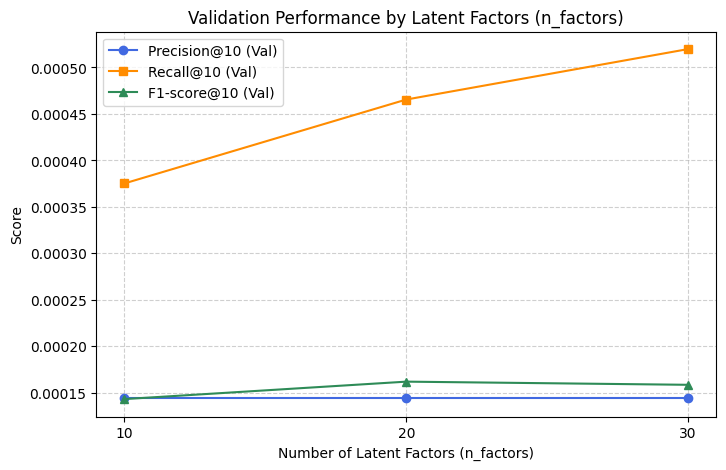

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# [수업 외 라이브러리 설명]
# - Dataset: pandas DataFrame을 Surprise 모델이 읽을 수 있는 데이터셋 객체로 변환하는 클래스
# - Reader: 평점 데이터의 최소~최대 범위(rating_scale)를 지정하는 클래스
# - SVD: Funk SVD(확률적 경사 하강법 기반 행렬 분해) 알고리즘을 구현한 협업 필터링 모델 클래스
from surprise import Dataset, Reader, SVD

# 1. 학습(train), 검증(validation), 테스트(test) 데이터 불러오기
train_df = pd.read_csv('train_ratings.csv')
val_df = pd.read_csv('validation_ratings.csv')
test_df = pd.read_csv('test_ratings.csv')
print("데이터 로드 완료")

# 2. Surprise 전용 학습 데이터셋 구성
# rating_scale=(1, 5): 평점 0점(미평가)을 제외한 1점~5점 범위 지정
reader = Reader(rating_scale=(1, 5))
# load_from_df: [사용자 ID, 아이템 ID, 평점] 순서의 컬럼을 Surprise 데이터 형식으로 변환
train_data = Dataset.load_from_df(train_df[['user_id', 'recipe_id', 'rating']], reader)
# build_full_trainset: 전체 학습 데이터를 모델 학습용 내부 인덱스 구조(Trainset)로 변환
trainset = train_data.build_full_trainset()

# 3. 검증(Validation) 평가 대상 유저 및 정답 준비 (train & val 모두 4점 이상 기록 보유)
train_pos_users = set(train_df[train_df['rating'] >= 4]['user_id'])
val_pos = val_df[val_df['rating'] >= 4]
val_user_gt = val_pos.groupby('user_id')['recipe_id'].apply(set).to_dict()
val_target_users = [uid for uid in val_user_gt.keys() if uid in train_pos_users]
print(f"검증 평가 대상 유저 수: {len(val_target_users)}명")

# 유저별로 train에서 이미 평가한 레시피 목록 저장 (추천 후보에서 제외하기 위함)
train_user_items = train_df.groupby('user_id')['recipe_id'].apply(set).to_dict()

# Surprise 내부 인덱스(inner_id)와 원본 레시피 ID(raw_id) 매핑 준비 (행렬 연산 최적화용)
all_inner_iids = list(trainset.all_items())
inner_to_raw_iid = [trainset.to_raw_iid(i) for i in all_inner_iids]
raw_to_inner_iid = {raw: inner for inner, raw in enumerate(inner_to_raw_iid)}

# 4. 잠재 요인 수(n_factors: 10, 20, 30)에 따른 검증 실험
factor_list = [10, 20, 30]
val_precisions, val_recalls, val_f1s = [], [], []

for nf in factor_list:
    print(f"Validation 실험 진행 중 (n_factors = {nf})")
    # [SVD 주요 파라미터 설명]
    # - n_factors: 사용자와 레시피의 숨은 취향을 표현하는 잠재 요인(Latent Factor) 차원 수
    # - n_epochs: 전체 학습 데이터를 반복 학습할 횟수 (SGD 반복 횟수)
    # - lr_all: 모든 파라미터 업데이트에 적용할 학습률 (Learning Rate)
    # - reg_all: 과적합 방지를 위한 L2 정규화 계수 (Regularization)
    # - random_state: 실행 시마다 동일한 결과를 재현하기 위한 난수 시드 고정값
    val_model = SVD(n_factors=nf, n_epochs=20, lr_all=0.005, reg_all=0.02, random_state=42)
    val_model.fit(trainset)

    p_scores, r_scores, f1_scores = [], [], []
    # model.bi: 각 레시피의 편향(Item Bias) 벡터 / model.qi: 레시피 잠재 요인 행렬
    bi = val_model.bi
    qi = val_model.qi

    for uid in val_target_users:
        gt_items = val_user_gt.get(uid, set())
        if not gt_items:
            continue

        # to_inner_uid: 원본 유저 ID를 Surprise 내부 정수 인덱스로 변환
        u_inner = trainset.to_inner_uid(uid)

        # np.dot: 행렬 내적 연산 함수. 개별 predict() 호출 대신 전체 레시피 점수를 한 번에 계산
        # model.pu[u_inner]: 해당 사용자의 잠재 요인 벡터
        scores = bi + np.dot(qi, val_model.pu[u_inner])

        # train에서 이미 평가한 레시피는 추천에서 제외하기 위해 점수를 -무한대(-np.inf)로 설정
        seen_items = train_user_items.get(uid, set())
        for s_item in seen_items:
            if s_item in raw_to_inner_iid:
                scores[raw_to_inner_iid[s_item]] = -np.inf

        # np.argpartition: 전체를 정렬하지 않고 상위 K개(10개) 인덱스만 빠르게 추출하는 함수
        top_10_idx = np.argpartition(scores, -10)[-10:]
        top_10_idx = top_10_idx[np.argsort(scores[top_10_idx])[::-1]]
        top_10 = [inner_to_raw_iid[idx] for idx in top_10_idx]

        # Precision@10, Recall@10, F1-score@10 계산
        hit = len(set(top_10) & gt_items)
        p = hit / 10.0
        r = hit / len(gt_items)
        # [피드백 반영] Precision과 Recall의 조화 평균인 F1-score@10 계산 추가
        f1 = (2 * p * r / (p + r)) if (p + r) > 0 else 0.0

        p_scores.append(p)
        r_scores.append(r)
        f1_scores.append(f1)

    val_precisions.append(np.mean(p_scores))
    val_recalls.append(np.mean(r_scores))
    val_f1s.append(np.mean(f1_scores))

# 5. 검증 결과 출력
print("\n[Validation 결과 요약]")
for nf, p, r, f1 in zip(factor_list, val_precisions, val_recalls, val_f1s):
    print(f"n_factors={nf} -> Precision@10: {p:.4f}, Recall@10: {r:.4f}, F1-score@10: {f1:.4f}")

# 6. 검증 성능 그래프 시각화
plt.figure(figsize=(8, 5))
plt.plot(factor_list, val_precisions, marker='o', label='Precision@10 (Val)', color='royalblue')
plt.plot(factor_list, val_recalls, marker='s', label='Recall@10 (Val)', color='darkorange')
plt.plot(factor_list, val_f1s, marker='^', label='F1-score@10 (Val)', color='seagreen')
plt.title('Validation Performance by Latent Factors (n_factors)')
plt.xlabel('Number of Latent Factors (n_factors)')
plt.ylabel('Score')
plt.xticks(factor_list)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

In [8]:
# 1. 최종 모델 학습 (Validation 결과 복잡도와 성능 균형을 고려해 n_factors=20 채택)
print("최종 SVD 모델(n_factors=20) 학습 시작")
model = SVD(n_factors=20, n_epochs=20, lr_all=0.005, reg_all=0.02, random_state=42)
model.fit(trainset)
print("모델 학습 완료")

# 2. 테스트(Test) 평가 대상 유저 및 정답 준비 (train & test 모두 4점 이상 기록 보유)
test_pos = test_df[test_df['rating'] >= 4]
test_user_gt = test_pos.groupby('user_id')['recipe_id'].apply(set).to_dict()
test_target_users = [uid for uid in test_user_gt.keys() if uid in train_pos_users]
print(f"최종 테스트 평가 대상 유저 수: {len(test_target_users)}명")

# 3. 전체 레시피 후보군(226,590개) 대상 Top-10 추천 및 평가 (행렬 내적 연산 사용)
test_precisions, test_recalls, test_f1s = [], [], []
bi = model.bi
qi = model.qi

for uid in test_target_users:
    gt_items = test_user_gt.get(uid, set())
    if not gt_items:
        continue

    u_inner = trainset.to_inner_uid(uid)
    scores = bi + np.dot(qi, model.pu[u_inner])

    # train에서 이미 평가한 레시피 제외
    seen_items = train_user_items.get(uid, set())
    for s_item in seen_items:
        if s_item in raw_to_inner_iid:
            scores[raw_to_inner_iid[s_item]] = -np.inf

    top_10_idx = np.argpartition(scores, -10)[-10:]
    top_10_idx = top_10_idx[np.argsort(scores[top_10_idx])[::-1]]
    top_10 = [inner_to_raw_iid[idx] for idx in top_10_idx]

    hit = len(set(top_10) & gt_items)
    p = hit / 10.0
    r = hit / len(gt_items)
    f1 = (2 * p * r / (p + r)) if (p + r) > 0 else 0.0

    test_precisions.append(p)
    test_recalls.append(r)
    test_f1s.append(f1)

print("\n[최종 테스트 평가 결과 (Baseline: n_factors=20)]")
print(f"Precision@10 : {np.mean(test_precisions):.4f}")
print(f"Recall@10    : {np.mean(test_recalls):.4f}")
print(f"F1-score@10  : {np.mean(test_f1s):.4f}")

최종 SVD 모델(n_factors=20) 학습 시작
모델 학습 완료
최종 테스트 평가 대상 유저 수: 1321명

[최종 테스트 평가 결과 (Baseline: n_factors=20)]
Precision@10 : 0.0002
Recall@10    : 0.0008
F1-score@10  : 0.0001


In [9]:
# glob: 특정 패턴(*.csv)에 맞는 폴더 내 파일 경로 목록을 탐색하는 파이썬 표준 라이브러리
import glob

# 1. 폴더 내 csv 파일에서 레시피 ID와 이름 매핑 사전 생성
id_to_name = {}
for fname in glob.glob("*.csv"):
    try:
        df_cols = pd.read_csv(fname, nrows=1).columns
        id_col = next((c for c in ['recipe_id', 'id', 'item_id'] if c in df_cols), None)
        name_col = next((c for c in ['name', 'recipe_name', 'title'] if c in df_cols), None)
        if id_col and name_col:
            df_temp = pd.read_csv(fname, usecols=[id_col, name_col]).dropna()
            id_to_name.update(dict(zip(df_temp[id_col], df_temp[name_col])))
    except Exception:
        continue

def get_recipe_str(rid):
    if rid in id_to_name and pd.notna(id_to_name[rid]):
        return f"{id_to_name[rid]} (ID: {rid})"
    return f"Recipe ID: {rid}"

# 2. 비교 대상 동일 사용자(187412) 기준 Top-10 추천 결과 추출
sample_uid = 187412
gt_items = test_user_gt.get(sample_uid, set())

u_inner = trainset.to_inner_uid(sample_uid)
scores = model.bi + np.dot(model.qi, model.pu[u_inner])

seen_items = train_user_items.get(sample_uid, set())
for s_item in seen_items:
    if s_item in raw_to_inner_iid:
        scores[raw_to_inner_iid[s_item]] = -np.inf

top_10_idx = np.argpartition(scores, -10)[-10:]
top_10_idx = top_10_idx[np.argsort(scores[top_10_idx])[::-1]]
sample_top10 = [inner_to_raw_iid[idx] for idx in top_10_idx]
sample_hits = set(sample_top10) & gt_items

# 3. 결과 출력
user_train_high = train_df[(train_df['user_id'] == sample_uid) & (train_df['rating'] >= 4)]
user_test_high = test_df[(test_df['user_id'] == sample_uid) & (test_df['rating'] >= 4)]

print(f"선정된 동일 사용자 ID : {sample_uid}")

print("\n해당 사용자가 train에서 4점 이상 준 레시피 (상위 5개) :")
for _, row in user_train_high.head(5).iterrows():
    print(f"  - {get_recipe_str(row['recipe_id'])} (평점: {row['rating']}점)")

print("\n해당 사용자가 test에서 4점 이상 준 실제 정답 레시피 :")
for _, row in user_test_high.iterrows():
    print(f"  - {get_recipe_str(row['recipe_id'])} (평점: {row['rating']}점)")

print("\n협업 필터링(SVD) 모델의 Top 10 추천 결과 :")
for idx, rid in enumerate(sample_top10, 1):
    r_inner = raw_to_inner_iid[rid]
    # 전체 평균 평점(global_mean) + 사용자 편향(bu) + 레시피 편향(bi) + 잠재 벡터 내적
    pred_score = model.trainset.global_mean + model.bu[u_inner] + model.bi[r_inner] + np.dot(model.qi[r_inner], model.pu[u_inner])
    # np.clip: 예측 평점이 실제 평점 범위(1.0~5.0)를 벗어나지 않도록 상·하한선을 제한하는 함수
    pred_score = np.clip(pred_score, 1.0, 5.0)

    match_str = " - test 정답 일치" if rid in sample_hits else ""
    print(f"  {idx}위: {get_recipe_str(rid)} (예측 평점: {pred_score:.2f}점){match_str}")

선정된 동일 사용자 ID : 187412

해당 사용자가 train에서 4점 이상 준 레시피 (상위 5개) :
  - cabbage waldorf salad (ID: 185883) (평점: 5점)
  - walnut sour cream coffee cake (ID: 12320) (평점: 5점)
  - pumpkin cobbler with pecan crunch (ID: 193359) (평점: 5점)
  - honey mustard pork chops (ID: 327418) (평점: 5점)
  - mole posole (ID: 138569) (평점: 5점)

해당 사용자가 test에서 4점 이상 준 실제 정답 레시피 :
  - flounder stuffed with shrimp and crabmeat (ID: 329528) (평점: 5점)

협업 필터링(SVD) 모델의 Top 10 추천 결과 :
  1위: flounder stuffed with shrimp and crabmeat (ID: 329528) (예측 평점: 5.00점) - test 정답 일치
  2위: the best shredded chicken  crock pot (ID: 108310) (예측 평점: 5.00점)
  3위: toffee dip with apples (ID: 21033) (예측 평점: 5.00점)
  4위: tgi friday s sizzling chicken and cheese (ID: 179487) (예측 평점: 5.00점)
  5위: a1b bacon burger bites on white polenta cakes  a1 (ID: 517863) (예측 평점: 5.00점)
  6위: good eats roast turkey (ID: 9954) (예측 평점: 5.00점)
  7위: dutch stamppot with rookworst (ID: 124192) (예측 평점: 5.00점)
  8위: ragu shuka  ragu (ID: 524863) (예측 평점: 5.00점)
  9위:

In [10]:
# [피드백 반영: 발표 이후 낮은 성능 개선을 위한 하이퍼파라미터 추가 실험]
# 잠재 요인 수(n_factors), 학습 횟수(n_epochs), 정규화 계수(reg_all)를 조정하여 성능 변화 비교
tuning_configs = [
    {"name": "기존 발표 모델", "n_factors": 20, "n_epochs": 20, "lr_all": 0.005, "reg_all": 0.02},
    {"name": "개선 시도 1 (차원/학습 증가)", "n_factors": 30, "n_epochs": 30, "lr_all": 0.005, "reg_all": 0.02},
    {"name": "개선 시도 2 (정규화 강화)", "n_factors": 30, "n_epochs": 30, "lr_all": 0.005, "reg_all": 0.05},
    {"name": "개선 시도 3 (고차원/학습률 조정)", "n_factors": 50, "n_epochs": 30, "lr_all": 0.003, "reg_all": 0.05},
]

print("[하이퍼파라미터 추가 튜닝 비교 결과 (Test Set)]")
for cfg in tuning_configs:
    exp_model = SVD(
        n_factors=cfg["n_factors"],
        n_epochs=cfg["n_epochs"],
        lr_all=cfg["lr_all"],
        reg_all=cfg["reg_all"],
        random_state=42
    )
    exp_model.fit(trainset)

    p_list, r_list, f1_list = [], [], []
    bi, qi = exp_model.bi, exp_model.qi

    for uid in test_target_users:
        gt_items = test_user_gt.get(uid, set())
        if not gt_items:
            continue

        u_inner = trainset.to_inner_uid(uid)
        scores = bi + np.dot(qi, exp_model.pu[u_inner])

        for s_item in train_user_items.get(uid, set()):
            if s_item in raw_to_inner_iid:
                scores[raw_to_inner_iid[s_item]] = -np.inf

        top_10_idx = np.argpartition(scores, -10)[-10:]
        top_10_idx = top_10_idx[np.argsort(scores[top_10_idx])[::-1]]
        top_10 = [inner_to_raw_iid[idx] for idx in top_10_idx]

        hit = len(set(top_10) & gt_items)
        p = hit / 10.0
        r = hit / len(gt_items)
        f1 = (2 * p * r / (p + r)) if (p + r) > 0 else 0.0

        p_list.append(p)
        r_list.append(r)
        f1_list.append(f1)

    print(f"- {cfg['name']} (factors={cfg['n_factors']}, epochs={cfg['n_epochs']}, reg={cfg['reg_all']})")
    print(f"  -> Precision@10: {np.mean(p_list):.4f} | Recall@10: {np.mean(r_list):.4f} | F1-score@10: {np.mean(f1_list):.4f}")

[하이퍼파라미터 추가 튜닝 비교 결과 (Test Set)]
- 기존 발표 모델 (factors=20, epochs=20, reg=0.02)
  -> Precision@10: 0.0002 | Recall@10: 0.0008 | F1-score@10: 0.0001
- 개선 시도 1 (차원/학습 증가) (factors=30, epochs=30, reg=0.02)
  -> Precision@10: 0.0002 | Recall@10: 0.0009 | F1-score@10: 0.0002
- 개선 시도 2 (정규화 강화) (factors=30, epochs=30, reg=0.05)
  -> Precision@10: 0.0000 | Recall@10: 0.0000 | F1-score@10: 0.0000
- 개선 시도 3 (고차원/학습률 조정) (factors=50, epochs=30, reg=0.05)
  -> Precision@10: 0.0000 | Recall@10: 0.0000 | F1-score@10: 0.0000
